# BioCRNpyler Model for Jung (2022)

The TMSE-BioCRNpyler library modeling results against *Programming Cell-Free Biosensors with DNA Strand Displacement Circuits* ([Jung et al., *Nature Chemical Biology* 2022](https://www.nature.com/articles/s41589-021-00962-9)).

**Modeling Approaches:**
* **Method 1:** Using the ODEs written as provided in the original manuscript's SI.
* **Method 2:** Using Hill functions to instantiate a repressible promoter.

## Global variables, definitions, and dependencies

In [1]:
from biocrnpyler import *
import numpy as np
import pylab as plt
import pandas as pd
from pathlib import Path

# Get base directory for BioCRNpyler scripts
directory = Path.cwd()
for p in [directory, *directory.parents]:
    if p.name == 'TMSE_BioCRNpyler_Library':
        base_dir = p
        break

# Location of scripts
tmse_mechs = (base_dir / 'mechanisms' / 'ToeholdMediatedStrandExchange.py').as_posix()
tmse_comps = (base_dir / 'components' / 'ToeholdMediatedStrandExchange.py').as_posix()
rna_comp = (base_dir / 'components' / 'RNAassembly.py').as_posix()

# Run scripts
%run {tmse_mechs}
%run {tmse_comps}
%run {rna_comp}

# Directory for Figures and Data
figs_dir = (base_dir / 'figures').as_posix()
data_dir = (base_dir / 'data').as_posix()

In [2]:
# Simulate all models - example for 2 hours
timepoints = np.linspace(0,2,5001)*3600


#Definition to un-nest lists that will be created by models
def flatten(t):
    return [item for sublist in t for item in sublist]

# Set a global default size for plots
plt.rcParams["figure.figsize"] = (7, 7)
font = 'MS Reference Sans Serif'
plt.rcParams["svg.fonttype"] = "none"
plt.rcParams['font.sans-serif'] = ['MS Reference Sans Serif']

# Plotting format
def FormatPlot(ylabel, fig_name, ymin = -0.02, ymax = 100):
    fs = 20
    
    plt.ylabel(ylabel,fontsize=fs)
    plt.xlabel('Time (h)',fontsize=fs)
    plt.legend(title='Input',frameon=False, loc='lower right',
               title_fontsize = fs, fontsize=fs)

    plt.ylim(ymin,ymax)
    plt.xlim(0,2)
    plt.xticks(fontsize=fs)
    plt.yticks(fontsize=fs)
    plt.xticks(np.arange(0, 5, 0.5))

## Transcription-factor-based Biosensors Simulation using TMSE-BioCRNpyler Library

In [3]:
# Define initial DNA and Reporter RNA (total components call = 3)
sim_inputs_tx = {'InvRT': ['Input','yellow'], 'InvRS': ['Input','blue']}, # Input DNA      
sim_inputs = {'OR_T':['Gate','yellow','green'],'OR_S':['Gate','blue','green'], 'RQ':['Reporter', 'green']}, # Gate DNA

# Components for RNA strands
step_tx = StrandExchangeMol(sim_inputs_tx, material_type= 'dna', transcription=True)
sd_dna = StrandExchangeMol(sim_inputs, material_type= 'dna')
step_tmse = TMSE(step_tx.rna+sd_dna.mol)

In [4]:
# Expression of RNA transcription
InvRt, InvRs = step_tx.rna
RNAP = Species('RNAP')

## tetO-Regulated Template
TetR = Species('TetR')
DtetO = Species('DtetO')
TetRD = Species('TetRD')
tet = Species('tet')
TetR_tet = Complex([TetR,tet])
RDtetO = Complex([RNAP,DtetO])

## smtO-Regulated Template
SmtB = Species('SmtB')
DsmtO = Species('DsmtO')
SmtBD = Species('SmtBD')
Zn = Species('Zn')
SmtB_Zn = Complex([SmtB,Zn])
RDsmtO = Complex([RNAP,DsmtO])

species_list = [RNAP,
                TetR, DtetO, TetRD, tet, TetR_tet, RDtetO, 
                SmtB, DsmtO, SmtBD, Zn, SmtB_Zn, RDsmtO]

# Reaction Rates
k_m_smtO = 0.1/2 # /uM-s
k_m_tetO = 0.1 # /uM-s
k_bind = 56. # /uM-s
k_unbind = 0.20 # /s
k_SD_S = 0.04 # /uM-s 
k_SD_T = 0.04 # /uM-s
k_SD = 0.04 # /uM-s
k_rep_S = 3 # /uM-s
k_derep_S = 0.18 # /s
k_rep_T = 2.98 # /uM-s
k_derep_T = 0.001 # /s
k_ind_S = 80 # /uM-s
k_unin_S = 0.1 # /s
k_ind_T = 4. # /uM-s
k_unin_T = 0.002 # /s

# Reaction Objects
rxns_list = [Reaction.from_massaction([TetR, DtetO], [TetRD], k_forward = k_rep_T, k_reverse=k_derep_T),
             Reaction.from_massaction([TetR, tet], [TetR_tet], k_forward = k_ind_T, k_reverse= k_unin_T),
             Reaction.from_massaction([RNAP, DtetO], [RDtetO], k_forward = k_bind, k_reverse=k_unbind),
             Reaction.from_massaction([RDtetO], [RNAP, DtetO, InvRt], k_forward = k_m_tetO),
             
             Reaction.from_massaction([SmtB, DsmtO], [SmtBD], k_forward = k_rep_S, k_reverse= k_derep_S),
             Reaction.from_massaction([SmtB, Zn], [SmtB_Zn], k_forward = k_ind_S, k_reverse= k_unin_S),
             Reaction.from_massaction([RNAP, DsmtO], [RDsmtO], k_forward = k_bind,  k_reverse= k_unbind),
             Reaction.from_massaction([RDsmtO], [RNAP, DsmtO, InvRs], k_forward = k_m_smtO)]

In [5]:
# Reactions (total reactions call = 1)
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}

# Parameters
TMSE_parameters = {"krev":0,
                   ParameterKey(mechanism = "one_step_tmse", part_id = "Gate_yellow_green", name = "kx"):k_SD_T,
                   ParameterKey(mechanism = "one_step_tmse", part_id = "Gate_blue_green", name = "kx"):k_SD_S,
                   ParameterKey(mechanism = "one_step_tmse", part_id = "Reporter_green", name = "krep"):k_SD,
                   }

# Make Mixture and Compile
M_txTMSEor = Mixture("txTMSEor", 
                       components=[step_tmse], 
                       parameters = TMSE_parameters,
                       mechanisms = sd_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_txTMSEor = M_txTMSEor.compile_crn()

# Add reactions
CRN_txTMSEor.add_reactions(rxns_list)

# Print CRN reactions
print(CRN_txTMSEor.pretty_print(show_rates = True, show_attributes = True, 
                                  show_materials = True, show_keys = True))

Species(N = 24) = {
tet (@ 0),  Zn (@ 0),  complex[TetR:tet] (@ 0),  TetRD (@ 0),  TetR (@ 0),  complex[SmtB:Zn] (@ 0),  SmtBD (@ 0),  SmtB (@ 0),  dna[Signal_green] (@ 0),  dna[Reporter_green] (@ 0),  dna[ReporterOut_green] (@ 0),  RNAP (@ 0),  dna[Output_yellow_green(ss)] (@ 0),  dna[Output_blue_green(ss)] (@ 0),  rna[Input_yellow] (@ 0),  rna[Input_blue] (@ 0),  dna[Gate_yellow_green] (@ 0),  dna[Gate_blue_green] (@ 0),  rnadna[GateOut_yellow_yellow] (@ 0),  rnadna[GateOut_blue_blue] (@ 0),  complex[DtetO:RNAP] (@ 0),  DtetO (@ 0),  complex[DsmtO:RNAP] (@ 0),  DsmtO (@ 0),  
}

Reactions (12) = [
0. dna[Gate_yellow_green]+rna[Input_yellow] --> dna[Output_yellow_green(ss)]+rnadna[GateOut_yellow_yellow]
 Kf=k_forward * dna_Gate_yellow_green * rna_Input_yellow
  k_forward=0.04
  found_key=(mech=one_step_tmse, partid=Gate_yellow_green, name=kx).
  search_key=(mech=one_step_tmse, partid=Gate_yellow_green, name=kx).

1. dna[Gate_blue_green]+rna[Input_blue] --> dna[Output_blue_green(ss)]+r

### Simulated using BioSCRAPE

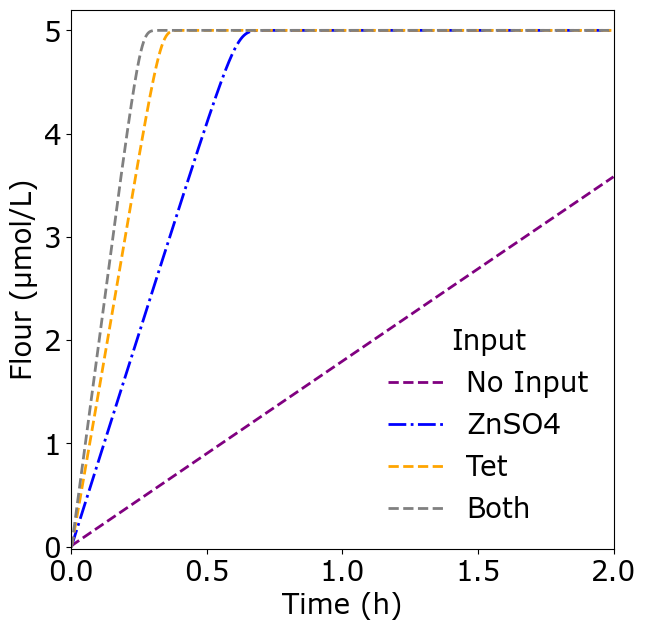

In [6]:
# Simulate
try:
    # Input templates
    tet_conc = [0,0,1,1]
    Zn_conc = [0,1,0,1]

    idx_conditions = {'No Input':['purple', '--'],
                      'ZnSO4': ['blue','-.'],
                      'Tet': ['orange','--'],
                      'Both': ['grey','--']}

    for tetc, znc, key in zip(tet_conc, Zn_conc, idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'DtetO': 0.05, 'DsmtO': 0.05,
                                      'RNAP': 0.1, 'TetR': 2.5, 'SmtB': 5,
                                      'dna_Gate_yellow_green':10, 'dna_Gate_blue_green':10,'dna_Reporter_green':5,
                                      'tet':tetc*10, 'Zn': znc*10}
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_txTMSEor.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                            initial_condition_dict = initial_concentration_dict)
        
        R.to_csv(f'{data_dir}/validation_Jung2022_OR_BioCRNpyler_{key}.csv')
        
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['dna_Signal_green'], label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])

    FormatPlot(ylabel='Flour (μmol/L)',ymax = 5.2, fig_name= 'Figure_2C')    
    plt.xlim(0,2)
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

## Not using TMSE-Library

In [7]:
# Components for RNA strands (total species call = 10)
InvRt = Species('InvRt')
InvRs = Species('InvRs')

OR_T = Species('OR_T')
OR_S = Species('OR_S')

InvD = Species('InvD')
GatedT = Species('GatedT')
GatedS = Species('GatedS')

RQ = Species('RQ')
SD = Species('SD')
Q = Species('Q')

strand_list = [InvRt, InvRs,
               OR_T, OR_S, InvD, GatedT, GatedS,
               RQ, SD, Q]

# Reaction Objects (total reactions call = 3)
strandrxns_list = [Reaction.from_massaction([InvRt, OR_T], [InvD, GatedT], k_forward = k_SD_T),
                   Reaction.from_massaction([InvRs, OR_S], [InvD, GatedS], k_forward = k_SD_S),
                   Reaction.from_massaction([InvD, RQ], [SD, Q], k_forward = k_SD)]

In [8]:
# Reaciton Objects for transcription
rxns_list = [Reaction.from_massaction([TetR, DtetO], [TetRD], k_forward = k_rep_T, k_reverse=k_derep_T),
             Reaction.from_massaction([TetR, tet], [TetR_tet], k_forward = k_ind_T, k_reverse= k_unin_T),
             Reaction.from_massaction([RNAP, DtetO], [RDtetO], k_forward = k_bind, k_reverse=k_unbind),
             Reaction.from_massaction([RDtetO], [RNAP, DtetO, InvRt], k_forward = k_m_tetO),
             
             Reaction.from_massaction([SmtB, DsmtO], [SmtBD], k_forward = k_rep_S, k_reverse= k_derep_S),
             Reaction.from_massaction([SmtB, Zn], [SmtB_Zn], k_forward = k_ind_S, k_reverse= k_unin_S),
             Reaction.from_massaction([RNAP, DsmtO], [RDsmtO], k_forward = k_bind,  k_reverse= k_unbind),
             Reaction.from_massaction([RDsmtO], [RNAP, DsmtO, InvRs], k_forward = k_m_smtO)]

# Make a CRN
CRN_txTMSEorV2 = ChemicalReactionNetwork(species = species_list+strand_list, reactions = rxns_list+strandrxns_list)


# Print CRN reactions
print(CRN_txTMSEorV2.pretty_print(show_rates = True, show_attributes = True, 
                                  show_materials = True, show_keys = False))

Species(N = 23) = {
tet (@ 0),  Zn (@ 0),  complex[TetR:tet] (@ 0),  TetRD (@ 0),  TetR (@ 0),  complex[SmtB:Zn] (@ 0),  SmtBD (@ 0),  SmtB (@ 0),  SD (@ 0),  RQ (@ 0),  RNAP (@ 0),  Q (@ 0),  OR_T (@ 0),  OR_S (@ 0),  InvRt (@ 0),  InvRs (@ 0),  InvD (@ 0),  GatedT (@ 0),  GatedS (@ 0),  complex[DtetO:RNAP] (@ 0),  DtetO (@ 0),  complex[DsmtO:RNAP] (@ 0),  DsmtO (@ 0),  
}

Reactions (11) = [
0. TetR+DtetO <--> TetRD
 Kf=k_forward * TetR * DtetO
 Kr=k_reverse * TetRD
  k_forward=2.98
  k_reverse=0.001

1. TetR+tet <--> complex[TetR:tet]
 Kf=k_forward * TetR * tet
 Kr=k_reverse * complex_TetR_tet_
  k_forward=4.0
  k_reverse=0.002

2. RNAP+DtetO <--> complex[DtetO:RNAP]
 Kf=k_forward * RNAP * DtetO
 Kr=k_reverse * complex_DtetO_RNAP_
  k_forward=56.0
  k_reverse=0.2

3. complex[DtetO:RNAP] --> RNAP+DtetO+InvRt
 Kf=k_forward * complex_DtetO_RNAP_
  k_forward=0.1

4. SmtB+DsmtO <--> SmtBD
 Kf=k_forward * SmtB * DsmtO
 Kr=k_reverse * SmtBD
  k_forward=3
  k_reverse=0.18

5. SmtB+Zn <--> c

### Simulated using BioSCRAPE

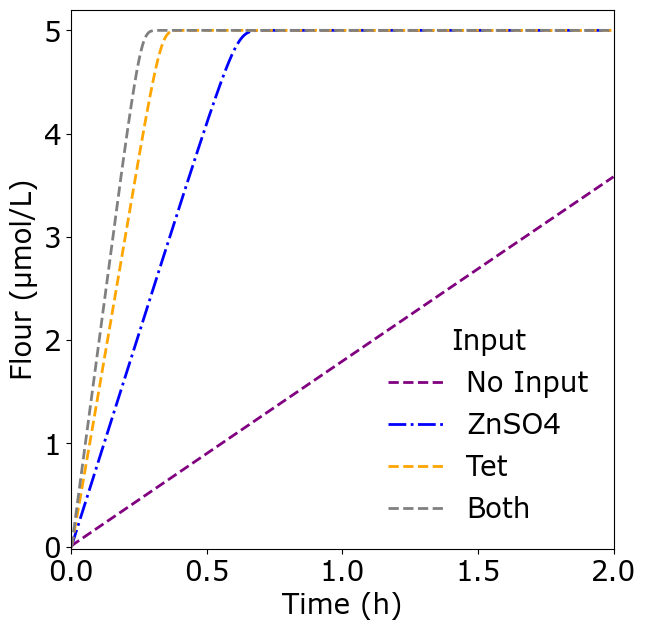

In [9]:
# Simulate
try:
    # Input templates
    tet_conc = [0,0,1,1]
    Zn_conc = [0,1,0,1]

    idx_conditions = {'No Input':['purple', '--'],
                      'ZnSO4': ['blue','-.'],
                      'Tet': ['orange','--'],
                      'Both': ['grey','--']}

    for tetc, znc, key in zip(tet_conc, Zn_conc, idx_conditions.keys()):
        # Create an initial condition so A has a non-zero value
        initial_concentration_dict = {'DtetO': 0.05, 'DsmtO': 0.05,
                                      'RNAP': 0.1, 'TetR': 2.5, 'SmtB': 5,
                                      'OR_T':10, 'OR_S':10,'RQ':5,
                                      'tet':tetc*10, 'Zn': znc*10}
        # This function can also take a filename keyword to save the file at the same time
        R = CRN_txTMSEorV2.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                            initial_condition_dict = initial_concentration_dict)
        
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R['time']/3600, R['SD'], label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])

    FormatPlot(ylabel='Flour (μmol/L)',ymax = 5.2, fig_name= 'Figure_2C')    
    plt.xlim(0,2)
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

## Using Hill functions

In [10]:
# Define initial DNA and Reporter RNA
sim_inputs_tx = {'DNA_1': ['Input',1], 'DNA_2': ['Input',3]}, # Input DNA      
sim_inputs = {'DNA_3':['Gate',1,2],'DNA_4':['Gate',3,2], 'DNA_5':['Reporter', 2]}, # Gate DNA

# Components
step_tx = StrandExchangeMol(sim_inputs_tx, material_type= 'dna', transcription=True)
sd_dna = StrandExchangeMol(sim_inputs, material_type= 'dna')
step_tmse = TMSE([sd_dna.mol,step_tx.rna])

# Create a DNA assembly with P_repressible for both its promoter
rna_Arep, rna_Brep = step_tx.rna
# Repressors
repA = Species("repA", material_type = "protein")
repB = Species("repB", material_type = "protein")

# Create a custom set of parameters
hill_parameters_A = {"k": 0.125, "n": 1, "K": 0.000336, "kleak":0.005}
hill_parameters_B = {"k": 0.1, "n": 1, "K": 0.000336, "kleak": 0.005}

# P_repressible
P_Arepressible = RepressiblePromoter("P_Arepressible", repressor  = repA, leak = True, parameters = hill_parameters_A)
P_Brepressible = RepressiblePromoter("P_Brepressible", repressor  = repB, leak = True, parameters = hill_parameters_B)

# DNA assembly 
repA_repressible_assembly = DNAassembly(name="repA_repressible_assembly", promoter=P_Arepressible, rbs=None, transcript= rna_Arep,protein = None)
repB_repressible_assembly = DNAassembly(name="repB_repressible_assembly", promoter=P_Brepressible, rbs=None, transcript= rna_Brep,protein = None)

# Activators and complxes
A, B = Species("A", material_type = "small_molecule"), Species("B", material_type = "small_molecule")
A_repA= ChemicalComplex(species=[A, repA])
B_repB= ChemicalComplex(species=[B, repB])

# Reactions
# Mechanism binding
mech_bind = One_Step_Binding()
binding_mechanisms = {mech_bind.mechanism_type:mech_bind}
# Mechanism strand displacement
mech_sd = OneStepTMSE()
sd_mechanisms = {mech_sd.mechanism_type:mech_sd}

# Parameters
TMSE_parameters = {"kx":0.04,
                   "krev":0,
                   "krep":0.04,
                   ParameterKey(mechanism = "one_step_binding", part_id = "protein_repA_small_molecule_A", name = "kb"):k_ind_T,#*.8
                   ParameterKey(mechanism = "one_step_binding", part_id = "protein_repA_small_molecule_A", name = "ku"):k_unin_T,
                   ParameterKey(mechanism = "one_step_binding", part_id = "protein_repB_small_molecule_B", name = "kb"):k_ind_S, #*1.5
                   ParameterKey(mechanism = "one_step_binding", part_id = "protein_repB_small_molecule_B", name = "ku"):k_unin_S,
                   }
# Make Mixture and Compile
M_txTMSEor_hill = Mixture("txTMSEor", 
                       components=[repA_repressible_assembly, repB_repressible_assembly, A_repA, B_repB, step_tmse], 
                       parameters=TMSE_parameters,
                       mechanisms=binding_mechanisms|sd_mechanisms)

# Compile the CRN with Mixture.compile_crn
CRN_txTMSEor_hill = M_txTMSEor_hill.compile_crn()

# Print CRN reactions
print(CRN_txTMSEor_hill.pretty_print(show_rates = True, show_attributes = True, 
                                  show_materials = True, show_keys = False))

Species(N = 19) = {
dna[repB_repressible_assembly] (@ 0),  protein[repB] (@ 0),  dna[repA_repressible_assembly] (@ 0),  protein[repA] (@ 0),  complex[protein[repB]:small_molecule[B]] (@ 0),  complex[protein[repA]:small_molecule[A]] (@ 0),  dna[Signal_2] (@ 0),  dna[Reporter_2] (@ 0),  dna[ReporterOut_2] (@ 0),  dna[Output_3_2(ss)] (@ 0),  dna[Output_1_2(ss)] (@ 0),  rna[Input_3] (@ 0),  rna[Input_1] (@ 0),  dna[Gate_3_2] (@ 0),  dna[Gate_1_2] (@ 0),  rnadna[GateOut_3_3] (@ 0),  rnadna[GateOut_1_1] (@ 0),  small_molecule[B] (@ 0),  small_molecule[A] (@ 0),  
}

Reactions (10) = [
0. dna[repA_repressible_assembly] --> dna[repA_repressible_assembly]+rna[Input_1]
 Kf = k dna[repA_repressible_assembly] / ( 1 + (protein[repA]/K)^1 )
  k=0.125
  K=0.000336
  n=1

1. dna[repA_repressible_assembly] --> dna[repA_repressible_assembly]+rna[Input_1]
 Kf=k_forward * dna_repA_repressible_assembly
  k_forward=0.005

2. dna[repB_repressible_assembly] --> dna[repB_repressible_assembly]+rna[Input_3]
 Kf 

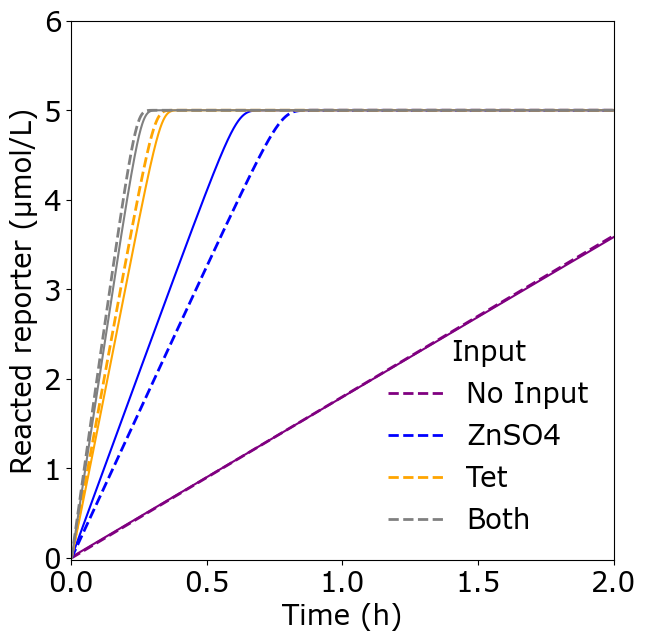

In [11]:
# Simulate
try:
    # Input templates
    tet_conc = [0,0,1,1]
    Zn_conc = [0,1,0,1]

    idx_conditions = {'No Input':['purple', '--'],
                      'ZnSO4': ['blue','--'],
                      'Tet': ['orange','--'],
                      'Both': ['grey','--']}

    for Ac, Bc, key in zip(tet_conc, Zn_conc, idx_conditions.keys()):
        # Jung2022 simulation
        Notsim_df = pd.read_csv(f'{data_dir}/validation_Jung2022_OR_{key}.csv')
        plt.plot(timepoints/3600, Notsim_df['SD'],  color = idx_conditions[key][0], linestyle = 'solid')
        
        # Hill simulation
        initial_concentration_dict_hill = {'dna_repA_repressible_assembly': 0.05, 'dna_repB_repressible_assembly': 0.05,
                                      'dna_Gate_1_2':10, 'dna_Gate_3_2':10, 'dna_Reporter_2':5,
                                      'protein_repA':2.5,'protein_repB':5,
                                      'small_molecule_A': Ac*10, 'small_molecule_B': Bc*10, 
                                      }
        # This function can also take a filename keyword to save the file at the same time
        R_hill = CRN_txTMSEor_hill.simulate_with_bioscrape_via_sbml(timepoints = timepoints,
                                                            initial_condition_dict = initial_concentration_dict_hill)
        
        R_hill.to_csv(f'{data_dir}/validation_Jung2022_OR_BioCRNpylerHill_{key}.csv')
        
        # Results are in a Pandas Dictionary and can be accessed via string-names of species
        plt.plot(R_hill['time']/3600, R_hill['dna_Signal_2'], label = key,
                 color = idx_conditions[key][0], linewidth = 2, linestyle = idx_conditions[key][1])

    FormatPlot(ylabel='Reacted reporter (μmol/L)',ymax = 6, fig_name= 'Figure_BioCRNpylerHillvJung2022')    
    plt.xlim(0,2)
    
except ModuleNotFoundError:
    print("Plotting Modules not installed.")

# Computing environment

In [12]:
%load_ext watermark
%watermark -v -p bioscrape,bokeh,jupyterlab,biocrnpyler

Python implementation: CPython
Python version       : 3.12.12
IPython version      : 9.12.0

bioscrape  : 1.2.1
bokeh      : 3.9.1
jupyterlab : 4.5.0
biocrnpyler: 1.3.2

